# 🧠 CardioIA | Ir Além 2: séries temporais e rede LIF

**Grupo Aura:** Murilo Salla (RM568041), Elias da Silva de Souza (RM568500) e Julia Duarte de Carvalho (RM567816). FIAP - Inteligência Artificial - Ano 2.

Damos continuidade aos classificadores da Fase 2 e à amostragem temporal de cinco segundos da Fase 3. Comparamos regressão logística sobre atributos estatísticos com uma rede recorrente de 24 neurônios LIF e leitura logística treinada. Os dados são **sintéticos**, independentes do Wokwi, dos pacientes Cleveland e dos ECGs da Fase 2.

Classificamos dois regimes do gerador: `regular_simulado` (oscilação lenta) e `oscilante_simulado` (oscilação rápida). Os rótulos não identificam arritmia, risco clínico ou doença. Não tratamos linhas de uma base transversal como uma série temporal.

**Como reproduzir:** executar da primeira à última célula em Python 3.12 com `config/fase3/requirements-neuromorfismo.txt`. O [guia detalhado](../../../document/fase3/neuromorfismo/README.md) também permite executar tudo pelo PowerShell, sem editor de notebook. A execução grava uma cópia em `.tools/runtime/fase3/neuromorfismo/`, preservando os resultados entregues.


In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/fase3/requirements-neuromorfismo.txt').is_file())
sys.path.insert(0, str(ROOT / 'src/fase3/neuromorfismo'))
import numpy as np
from experimento import (gerar_sessoes, dividir_sessoes, criar_janelas,
                         atributos_tradicionais, RedeLIF, executar, SEED)
# Cada execução usa uma pasta nova: o visualizador do Windows pode manter
# os PNGs anteriores mapeados e impedir sua regravação.
from tempfile import mkdtemp
NOTEBOOK_OUTPUTS = ROOT / '.tools/runtime/fase3/neuromorfismo/notebooks'
NOTEBOOK_OUTPUTS.mkdir(parents=True, exist_ok=True)
OUT = Path(mkdtemp(prefix='execucao-', dir=NOTEBOOK_OUTPUTS))
print('Python:', sys.version.split()[0])
print('Raiz localizada: pasta que contém src e config')
print('Saída local:', OUT.relative_to(ROOT))


Python: 3.12.10
Raiz localizada: pasta que contém src e config
Saída local: .tools\runtime\fase3\neuromorfismo\notebooks\execucao-mk206xaq


## 1. Geramos sessões e separamos antes das janelas

Geramos 240 sessões independentes, cada uma com 120 amostras (10 minutos; cinco segundos por amostra). Ambas as classes compartilham faixa de média (65-110 BPM), amplitude (6-17 BPM), ruído e deriva. Diferem no período sorteado: 35-65 amostras na classe 0 e 9-18 na classe 1. A semente 42 fixa os sorteios.

Dividimos 144/48/48 sessões em treino/validação/teste, estratificando as classes. Só então recortamos nove janelas por sessão, de 24 amostras (120 segundos) com passo de 12. A sobreposição fica dentro da própria partição. As sessões são artificiais, não pessoas nem visitas de pacientes.


In [2]:
series, labels = gerar_sessoes(SEED)
splits = dividir_sessoes(labels, SEED)
assert not (set(splits['treino']) & set(splits['teste']))
assert not (set(splits['validacao']) & set(splits['teste']))
assert not (set(splits['treino']) & set(splits['validacao']))
windows = {k: criar_janelas(series, labels, ids) for k, ids in splits.items()}
for name, ids in splits.items():
    print(name, ':', len(ids), 'sessões;', len(windows[name][0]), 'janelas; classes:', np.bincount(labels[ids]).tolist())
print('Uma janela do treino:', windows['treino'][0][0].round(1))


treino : 144 sessões; 1296 janelas; classes: [72, 72]
validacao : 48 sessões; 432 janelas; classes: [24, 24]
teste : 48 sessões; 432 janelas; classes: [24, 24]
Uma janela do treino: [103.7 106.9 111.4 113.5 107.3 113.8 108.1 104.  105.2 101.1 103.5 105.4
 110.1 113.2  99.  106.2  99.2 105.1 101.5  93.7 104.9  97.2  96.4  93. ]


## 2. Definimos a comparação antes de consultar o teste

**Tradicional:** oito atributos por janela: média, desvio, mínimo, máximo, raiz da média das diferenças ao quadrado, diferença absoluta média, autocorrelação de lag 1 e diferença final-inicial. Incluímos atributos temporais para evitar uma comparação restrita à média.

**Neuromórfico:** rede recorrente de 24 neurônios LIF com pesos internos fixos pela semente. Codificamos nível acima/abaixo da média de treino e variação positiva/negativa. Integramos `v ← v + (dt/tau) × (-v + I)`; ao atingir 1, emitimos um spike, reiniciamos em 0 e aplicamos dois passos refratários. Usamos `dt=1 ms`, `tau=10 ms` e 20 passos neurais por leitura. Os 20 ms do modelo representam uma leitura de cinco segundos: são relógios diferentes, sem calibração biológica.

Extraímos 96 taxas de spikes (quatro blocos × 24 neurônios) e 24 potenciais finais. O reservatório LIF participa efetivamente da previsão; treinamos uma saída logística sobre seus 120 atributos, sem STDP nem treinamento dos pesos internos. Reiniciamos o estado a cada janela.

Os dois métodos usam normalização ajustada no treino e saída logística com `C ∈ {0.01, 0.1, 1, 10}`. Escolhemos C pelo F1 macro das sessões de **validação**; empate favorece o primeiro C. Não retreinamos com validação e não alteramos parâmetros depois dos resultados de teste. A probabilidade de uma sessão é a média de suas nove janelas; decisão fixa em 0,5.


In [3]:
xt = windows['treino'][0]
print('Tradicional:', atributos_tradicionais(xt).shape)
lif = RedeLIF(SEED).fit(xt)  # Somente treino ajusta as escalas.
features, potential, spikes = lif.transform(xt[:1], trace=True)
print('LIF:', features.shape, '| dinâmica:', potential.shape, '| spikes:', int(spikes.sum()))
assert spikes.sum() > 0
assert np.isfinite(features).all()


Tradicional: (1296, 8)
LIF: (1, 120) | dinâmica: (480, 24) | spikes: 1035


## 3. Treinamos, selecionamos na validação e avaliamos o teste separado

Executamos o protocolo completo definido em `src/fase3/neuromorfismo/experimento.py`. Os dois modelos veem as mesmas janelas e sessões. Medimos acurácia, acurácia balanceada, F1 macro, precisão, recall e ROC-AUC. As métricas principais são por sessão (48 unidades independentes); as métricas de janelas são secundárias, pois suas sobreposições não representam novas observações independentes.

Calculamos intervalos de 95% por bootstrap estratificado de 2.000 reamostragens das sessões de teste, incluindo a diferença pareada de acurácia balanceada LIF menos tradicional. Não usamos esses intervalos para escolher C. Tempos incluem transformação e execução em CPU, uma medição por método; não são consumo energético nem desempenho de chip neuromórfico.


In [4]:
summary = executar(OUT, SEED)
for name, result in summary['modelos'].items():
    print('\nMODELO:', name, '| C escolhido:', result['C_escolhido'])
    print('Busca na validação:', result['busca_validacao'])
    print('Métricas no teste por sessão:', json.dumps(result['sessoes'], ensure_ascii=False))
    print('Tempos CPU (s): ajuste', round(result['ajuste_com_transformacao_s'], 4),
          '| transformação + previsão', round(result['previsao_com_transformacao_s'], 4))
print('\nIC95 por sessão:', summary['ic95_bootstrap_sessoes'])
print('SHA-256 dos sinais e rótulos:', summary['sha256_sinais_rotulos'])



MODELO: tradicional | C escolhido: 10.0
Busca na validação: [{'C': 0.01, 'f1_macro_validacao_sessoes': 0.6444444444444444}, {'C': 0.1, 'f1_macro_validacao_sessoes': 0.6873643074250977}, {'C': 1.0, 'f1_macro_validacao_sessoes': 0.7699346405228757}, {'C': 10.0, 'f1_macro_validacao_sessoes': 0.791304347826087}]
Métricas no teste por sessão: {"acuracia": 0.9166666666666666, "acuracia_balanceada": 0.9166666666666667, "f1_macro": 0.9165217391304348, "precisao_classe1": 0.8846153846153846, "recall_classe1": 0.9583333333333334, "roc_auc": 0.9722222222222222, "matriz_confusao": [[21, 3], [1, 23]]}
Tempos CPU (s): ajuste 0.0315 | transformação + previsão 0.0007

MODELO: lif | C escolhido: 0.01
Busca na validação: [{'C': 0.01, 'f1_macro_validacao_sessoes': 0.6039947894051237}, {'C': 0.1, 'f1_macro_validacao_sessoes': 0.5826086956521739}, {'C': 1.0, 'f1_macro_validacao_sessoes': 0.6026143790849673}, {'C': 10.0, 'f1_macro_validacao_sessoes': 0.6026143790849673}]
Métricas no teste por sessão: {"acu

## 4. Visualizamos os sinais, os erros e a atividade de spikes

As matrizes apresentam rótulo real nas linhas e previsão nas colunas. Os dois sinais exemplificados vêm do teste para ilustração posterior à avaliação; não selecionamos parâmetros com esses exemplos. No gráfico LIF, o potencial mostrado é o valor antes do reset e os pontos representam os spikes reais da rede.


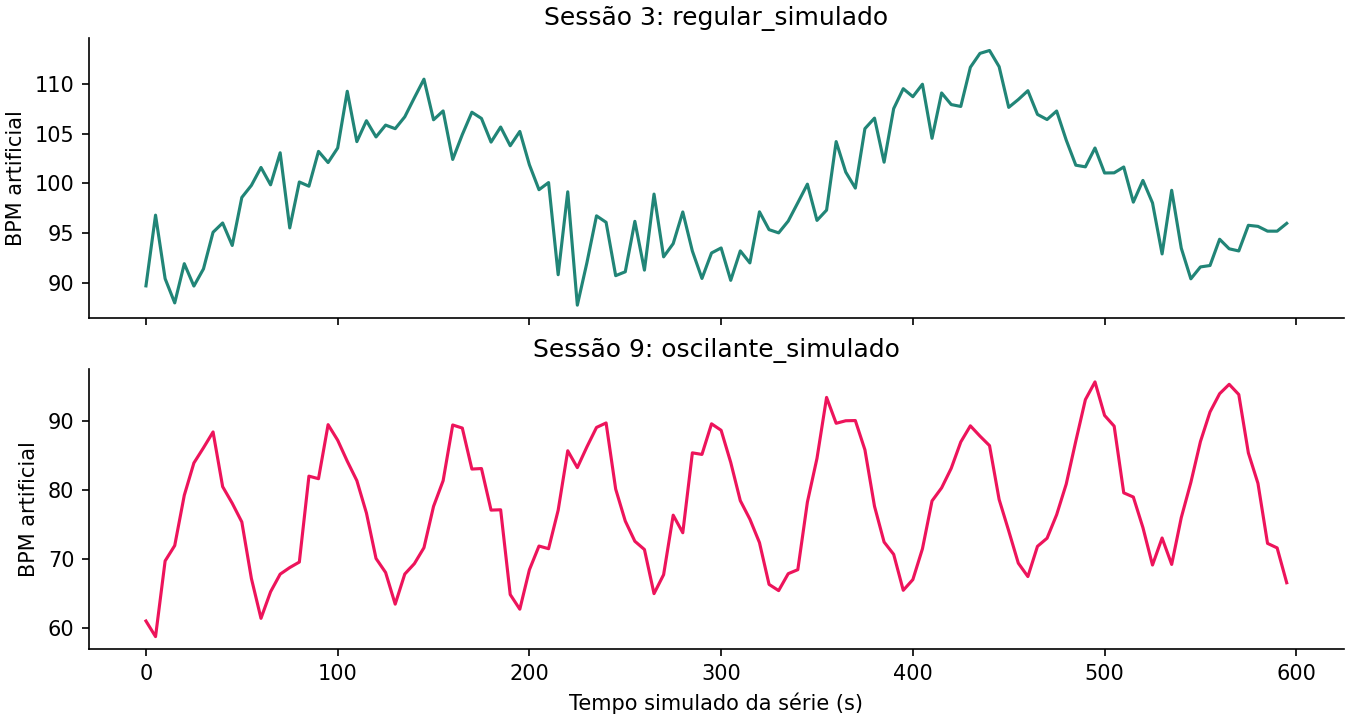

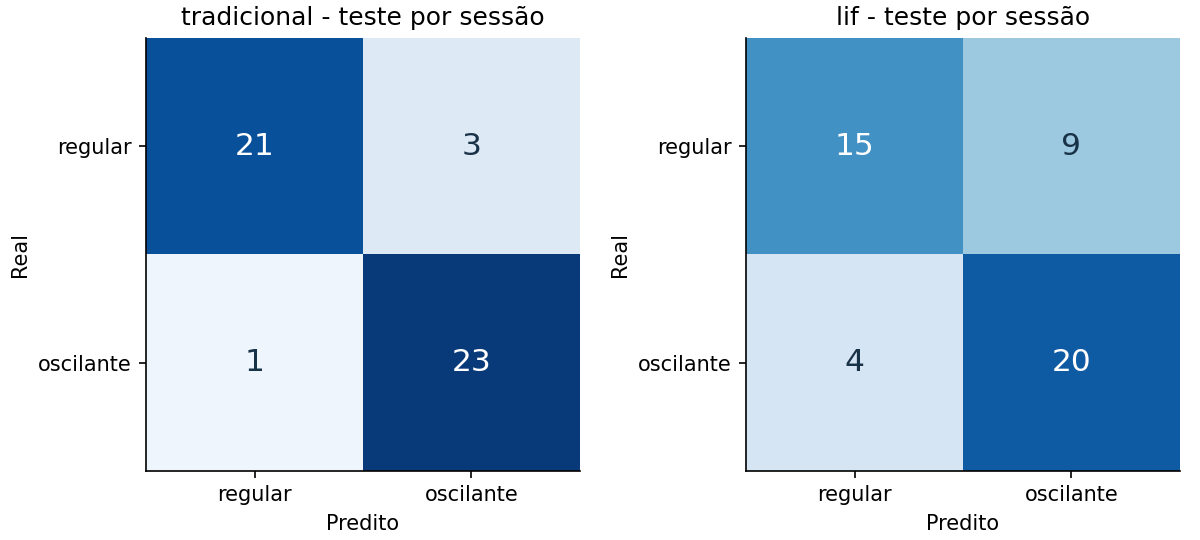

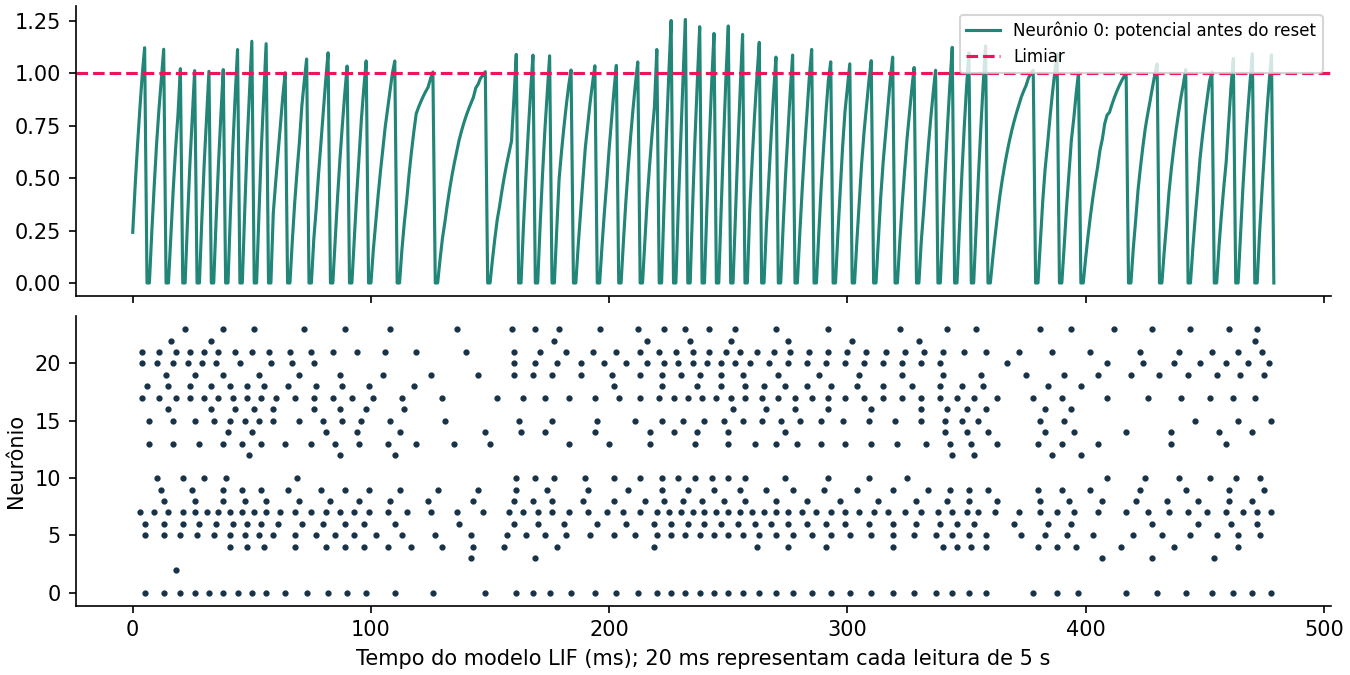

tradicional - sessões classificadas incorretamente: [65, 135, 155, 213]
lif - sessões classificadas incorretamente: [9, 51, 65, 71, 135, 146, 150, 155, 165, 194, 203, 209, 213]
Primeiras previsões: [{'sessao': 3, 'rotulo': 0, 'tradicional': 0.209507094852215, 'lif': 0.23722586362423254}, {'sessao': 9, 'rotulo': 1, 'tradicional': 0.5831357102887951, 'lif': 0.4207099228470431}, {'sessao': 19, 'rotulo': 1, 'tradicional': 0.711309539181154, 'lif': 0.6536778307198584}, {'sessao': 25, 'rotulo': 1, 'tradicional': 0.73327447910753, 'lif': 0.6419215708014456}]


In [5]:
for filename in ['series.png', 'matrizes_confusao.png', 'atividade_lif.png']:
    display(Image(filename=str(OUT / filename)))
for name, result in summary['modelos'].items():
    print(name, '- sessões classificadas incorretamente:', result['erros_sessoes'])
predictions = json.loads((OUT / 'previsoes_teste.json').read_text(encoding='utf-8'))
print('Primeiras previsões:', predictions['sessoes'][:4])


## 5. Interpretamos sem generalizar além do experimento

Comparamos pipelines com representações distintas (8 atributos versus 120), embora ambos terminem em regressão logística. Portanto, o resultado não isola o efeito de um único neurônio ou de igual capacidade de parâmetros. Uma diferença em teste não demonstra superioridade geral. O LIF acrescenta dinâmica, spikes e memória; a solução tradicional oferece execução mais simples e atributos mais interpretáveis.

Os rótulos reproduzem regimes de oscilação escolhidos no gerador. Mesmo pontuação alta demonstra apenas separação desses regimes artificiais. Os sinais não são ECG, intervalos RR de pacientes nem validação de arritmias; não ligamos o modelo aos alertas do painel. Precisaríamos de dados reais rotulados, avaliação por paciente, validação externa e revisão especializada antes de discutir aplicação clínica.

A semente única e o conjunto pequeno limitam a conclusão. O bootstrap estima incerteza de amostragem deste teste; não inclui incerteza de outras fontes, geradores ou sementes. Não medimos energia, hardware ou latência do ESP32.


In [6]:
lo, hi = summary['ic95_bootstrap_sessoes']['diferenca_lif_menos_tradicional']
if lo <= 0 <= hi:
    print('O intervalo da diferença inclui zero: não afirmamos vantagem consistente neste teste.')
else:
    print('O intervalo não inclui zero neste conjunto sintético. Isso não demonstra superioridade geral ou clínica.')
print('Limites registrados:')
for item in summary['limites']:
    print('-', item)
print('Versões:', summary['ambiente'])


O intervalo não inclui zero neste conjunto sintético. Isso não demonstra superioridade geral ou clínica.
Limites registrados:
- Rotulos do regime gerador; nao sao arritmia ou diagnostico.
- Mesma media de BPM pode pertencer a ambas as classes.
- Janelas da mesma sessao se sobrepoem; metricas principais sao por sessao.
- Tempos de uma execucao em CPU, sem benchmark energetico ou de hardware.
- Comparacao de pipelines: 8 atributos tradicionais versus 120 LIF.
- Nao treinamos pesos internos nem validamos em pacientes reais.
Versões: {'python': '3.12.10', 'sistema': 'Windows', 'numpy': '2.3.4', 'scipy': '1.16.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.7'}


## 6. Referências e próximos passos da entrega

- Gerstner et al., *Neuronal Dynamics*, [modelo LIF, seção 1.3](https://neuronaldynamics.epfl.ch/online/Ch1.S3.html): integração, fuga, disparo e reset.
- Gerstner et al., [reservoir computing, seção 20.1](https://neuronaldynamics.epfl.ch/online/Ch20.S1.html): dinâmica interna e leitura treinada.
- Scikit-learn, [prevenção de vazamento de dados](https://scikit-learn.org/stable/common_pitfalls.html): ajuste das transformações com treino.

Adaptamos as equações em NumPy para uma rede didática própria; não reproduzimos os experimentos do livro. A base e o código deste desafio são do grupo. Conferir o relatório comparativo de duas páginas e o roteiro de vídeo no guia. A revisão técnica foi concluída em 28/10/2026. A gravação, publicação não listada e inclusão do link no README permanecem pendentes até sua realização e conferência.
